PROJECT NAME : SKIN DISSORDER PREDICTIONS

PROJECT TYPE : MACHINE LEARNING-CLASSIFICATION

CONTRIBUTION : INDIVIDUAL

PROJECT SUMMARY :

The Skin Disorder Prediction project aims to classify different types of skin disorders using machine learning techniques. The project uses a dermatology dataset containing clinical features and six target classes. Exploratory Data Analysis (EDA) and data preprocessing are performed to understand the dataset and prepare it for model training. Three machine learning algorithms—Random Forest, Support Vector Machine (SVM), and Decision Tree—are implemented and compared using accuracy, precision, recall, F1-score, and confusion matrices. The best-performing model is identified based on the evaluation results. This project demonstrates the application of machine learning in healthcare data analysis and automated skin disorder classification for educational and research purposes.

PROBLEM STATEMENT :

Skin disorders can have similar clinical symptoms, making their classification a challenging task. Manual analysis of clinical features may require considerable time and medical expertise. Therefore, there is a need to explore machine learning techniques that can classify skin disorders based on available clinical data.

The main objective of this project is to develop a machine learning-based skin disorder classification system using the Dermatology dataset. Three algorithms—Random Forest, Support Vector Machine (SVM), and Decision Tree—are implemented and compared using performance metrics such as accuracy, precision, recall, and F1-score. The system aims to identify the best-performing model for classifying the six skin disorder categories in the dataset.

This project demonstrates the potential of machine learning in healthcare data analysis and educational research, but its predictions are not intended to replace professional medical diagnosis.

IMPORT LIBRARIES

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

LOAD DATASET

In [5]:
df=pd.read_csv("/content/dataset_35_dermatology (1).csv")

In [6]:
df

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
361,2,1,1,0,1,0,0,0,0,0,...,0,0,1,0,0,0,2,0,25,4
362,3,2,1,0,1,0,0,0,0,0,...,1,0,1,0,0,0,2,0,36,4
363,3,2,2,2,3,2,0,2,0,0,...,0,3,0,3,0,0,2,3,28,3
364,2,1,3,1,2,3,0,2,0,0,...,0,2,0,1,0,0,2,3,50,3


BASIC CHECKS

In [7]:
df.head()

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45,3


In [8]:
df.tail()

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
361,2,1,1,0,1,0,0,0,0,0,...,0,0,1,0,0,0,2,0,25,4
362,3,2,1,0,1,0,0,0,0,0,...,1,0,1,0,0,0,2,0,36,4
363,3,2,2,2,3,2,0,2,0,0,...,0,3,0,3,0,0,2,3,28,3
364,2,1,3,1,2,3,0,2,0,0,...,0,2,0,1,0,0,2,3,50,3
365,3,2,2,0,0,0,0,0,3,3,...,2,0,0,0,0,0,3,0,35,1


In [9]:
df.shape

(366, 35)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                                    Non-Null Count  Dtype 
---  ------                                    --------------  ----- 
 0   erythema                                  366 non-null    int64 
 1   scaling                                   366 non-null    int64 
 2   definite_borders                          366 non-null    int64 
 3   itching                                   366 non-null    int64 
 4   koebner_phenomenon                        366 non-null    int64 
 5   polygonal_papules                         366 non-null    int64 
 6   follicular_papules                        366 non-null    int64 
 7   oral_mucosal_involvement                  366 non-null    int64 
 8   knee_and_elbow_involvement                366 non-null    int64 
 9   scalp_involvement                         366 non-null    int64 
 10  family_history                            366 non-

In [11]:
df.describe()

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,class
count,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,...,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000
mean,2.068306,1.795082,1.549180,1.366120,0.633880,0.448087,0.166667,0.377049,0.614754,0.519126,...,0.393443,0.464481,0.456284,0.953552,0.453552,0.103825,0.114754,1.866120,0.554645,2.803279
std,0.664753,0.701527,0.907525,1.138299,0.908016,0.957327,0.570588,0.834147,0.982979,0.905639,...,0.849406,0.864899,0.954873,1.130172,0.954744,0.450433,0.488723,0.726108,1.105908,1.597803
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
50%,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,3.000000
75%,2.000000,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,0.000000,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,2.000000,0.000000,4.000000
max,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,...,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,6.000000


In [12]:
df.columns

Index(['erythema', 'scaling', 'definite_borders', 'itching',
       'koebner_phenomenon', 'polygonal_papules', 'follicular_papules',
       'oral_mucosal_involvement', 'knee_and_elbow_involvement',
       'scalp_involvement', 'family_history', 'melanin_incontinence',
       'eosinophils_in_the_infiltrate', 'PNL_infiltrate',
       'fibrosis_of_the_papillary_dermis', 'exocytosis', 'acanthosis',
       'hyperkeratosis', 'parakeratosis', 'clubbing_of_the_rete_ridges',
       'elongation_of_the_rete_ridges',
       'thinning_of_the_suprapapillary_epidermis', 'spongiform_pustule',
       'munro_microabcess', 'focal_hypergranulosis',
       'disappearance_of_the_granular_layer',
       'vacuolisation_and_damage_of_basal_layer', 'spongiosis',
       'saw-tooth_appearance_of_retes', 'follicular_horn_plug',
       'perifollicular_parakeratosis', 'inflammatory_monoluclear_inflitrate',
       'band-like_infiltrate', 'Age', 'class'],
      dtype='object')

In [13]:
df.dtypes

,0
erythema,int64
scaling,int64
definite_borders,int64
itching,int64
koebner_phenomenon,int64
polygonal_papules,int64
follicular_papules,int64
oral_mucosal_involvement,int64
knee_and_elbow_involvement,int64
scalp_involvement,int64


CHECK MISSING VALUES

Missing values in each column:


,0
Age,8



Total missing values: 8


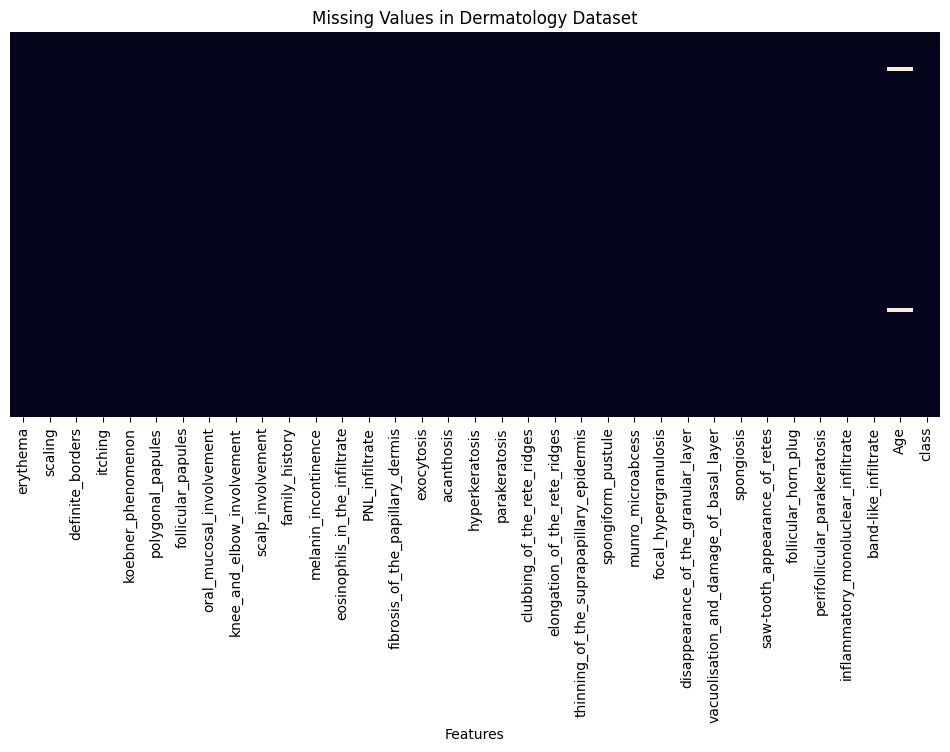

In [14]:
# Replace question marks and empty strings with NaN
df.columns = df.columns.str.strip()
df = df.replace(r'^\s*\?\s*$', np.nan, regex=True)
df = df.replace(r'^\s*$', np.nan, regex=True)

print("Missing values in each column:")
missing_values = df.isnull().sum()
display(missing_values[missing_values > 0])

print("\nTotal missing values:", df.isnull().sum().sum())

# Visualize missing values
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values in Dermatology Dataset")
plt.xlabel("Features")
plt.show()

STATISTICAL ANALYSIS

This shows the mean, standard deviation, minimum, maximum, and quartiles for numerical columns.

In [15]:
print("Statistical summary of numerical features:")
display(df.describe().T)

print("\nSummary including all columns:")
display(df.describe(include="all").T)

Statistical summary of numerical features:


,count,mean,std,min,25%,50%,75%,max
erythema,366.0,2.068306,0.664753,0.0,2.0,2.0,2.0,3.0
scaling,366.0,1.795082,0.701527,0.0,1.0,2.0,2.0,3.0
definite_borders,366.0,1.549180,0.907525,0.0,1.0,2.0,2.0,3.0
itching,366.0,1.366120,1.138299,0.0,0.0,1.0,2.0,3.0
koebner_phenomenon,366.0,0.633880,0.908016,0.0,0.0,0.0,1.0,3.0
polygonal_papules,366.0,0.448087,0.957327,0.0,0.0,0.0,0.0,3.0
follicular_papules,366.0,0.166667,0.570588,0.0,0.0,0.0,0.0,3.0
oral_mucosal_involvement,366.0,0.377049,0.834147,0.0,0.0,0.0,0.0,3.0
knee_and_elbow_involvement,366.0,0.614754,0.982979,0.0,0.0,0.0,1.0,3.0
scalp_involvement,366.0,0.519126,0.905639,0.0,0.0,0.0,1.0,3.0



Summary including all columns:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
erythema,366.0,NaN,NaN,NaN,2.068306,0.664753,0.0,2.0,2.0,2.0,3.0
scaling,366.0,NaN,NaN,NaN,1.795082,0.701527,0.0,1.0,2.0,2.0,3.0
definite_borders,366.0,NaN,NaN,NaN,1.54918,0.907525,0.0,1.0,2.0,2.0,3.0
itching,366.0,NaN,NaN,NaN,1.36612,1.138299,0.0,0.0,1.0,2.0,3.0
koebner_phenomenon,366.0,NaN,NaN,NaN,0.63388,0.908016,0.0,0.0,0.0,1.0,3.0
polygonal_papules,366.0,NaN,NaN,NaN,0.448087,0.957327,0.0,0.0,0.0,0.0,3.0
follicular_papules,366.0,NaN,NaN,NaN,0.166667,0.570588,0.0,0.0,0.0,0.0,3.0
oral_mucosal_involvement,366.0,NaN,NaN,NaN,0.377049,0.834147,0.0,0.0,0.0,0.0,3.0
knee_and_elbow_involvement,366.0,NaN,NaN,NaN,0.614754,0.982979,0.0,0.0,0.0,1.0,3.0
scalp_involvement,366.0,NaN,NaN,NaN,0.519126,0.905639,0.0,0.0,0.0,1.0,3.0


We'll keep the target column separate and convert the features to numeric values.

CLEAN THE DATA

In [27]:
# Identify the target column
target_col = next(
    (col for col in df.columns if col.lower() == "class"),
    None
)

if target_col is None:
    raise ValueError("Target column 'class' not found.")

# Remove records with missing target values
df = df.dropna(subset=[target_col]).copy()

# Convert columns to numeric
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Separate features and target
X_eda = df.drop(columns=[target_col])
y_eda = df[target_col]

print("EDA cleaning completed!")
print("Features:", X_eda.shape[1])
print("Records:", X_eda.shape[0])

print("\nTarget classes:")
print(sorted(y_eda.dropna().unique()))

print("\nClass counts:")
display(y_eda.value_counts().sort_index())

EDA cleaning completed!
Features: 34
Records: 366

Target classes:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]

Class counts:


,count
class,
1,112
2,61
3,72
4,49
5,52
6,20


EDA VISUALIZATIONS

ANALYZE THE TARGET VARIABLE

This graph shows how many records belong to each skin disorder class.

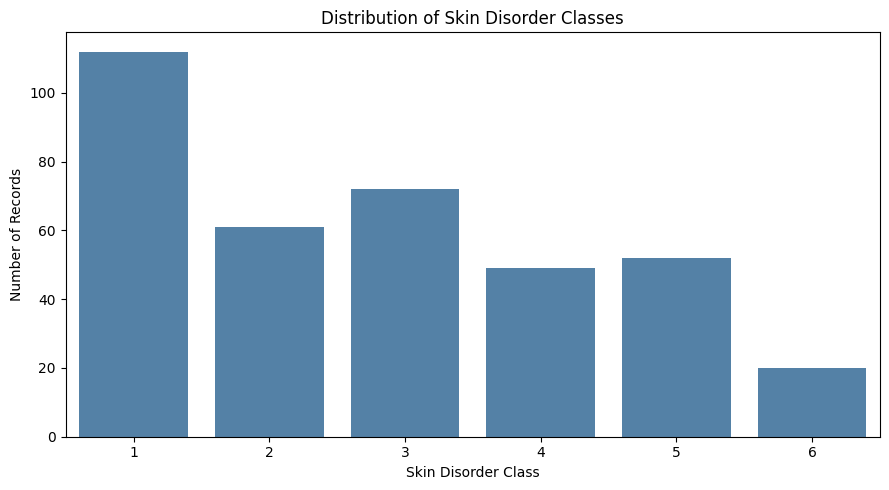


Class percentages:


,Percentage (%)
class,
1,30.60
2,16.67
3,19.67
4,13.39
5,14.21
6,5.46


In [17]:
plt.figure(figsize=(9, 5))

sns.countplot(
    x=y_eda,
    order=sorted(y_eda.dropna().unique()),
    color="steelblue"
)

plt.title("Distribution of Skin Disorder Classes")
plt.xlabel("Skin Disorder Class")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

print("\nClass percentages:")
display(
    (y_eda.value_counts(normalize=True).sort_index() * 100)
    .round(2)
    .rename("Percentage (%)")
    .to_frame()
)

ANALYZE THE AGE FEATURE

Age is useful to explore because it is a demographic feature in this dataset.

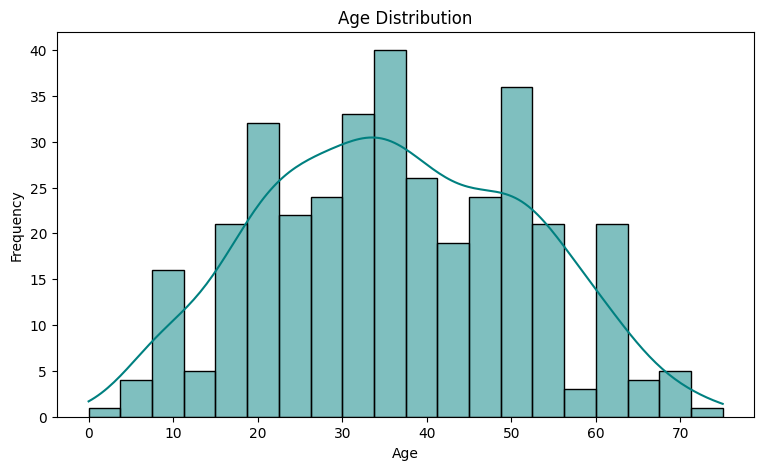

Age summary:


,Age
count,358.000000
mean,36.296089
std,15.324557
min,0.000000
25%,25.000000
50%,35.000000
75%,49.750000
max,75.000000


In [18]:
age_col = next(
    (col for col in X_eda.columns if col.strip().lower() == "age"),
    None
)

if age_col is not None:
    plt.figure(figsize=(9, 5))
    sns.histplot(
        X_eda[age_col].dropna(),
        bins=20,
        kde=True,
        color="teal"
    )
    plt.title("Age Distribution")
    plt.xlabel("Age")
    plt.ylabel("Frequency")
    plt.show()

    print("Age summary:")
    display(X_eda[age_col].describe())
else:
    print("Age column not found. Check the dataset column names.")

ANALYZE INDIVIDUAL FEATURE DISTRIBUTION

Most dermatology features describe clinical signs and symptoms. This code displays the distributions of the first six available features.

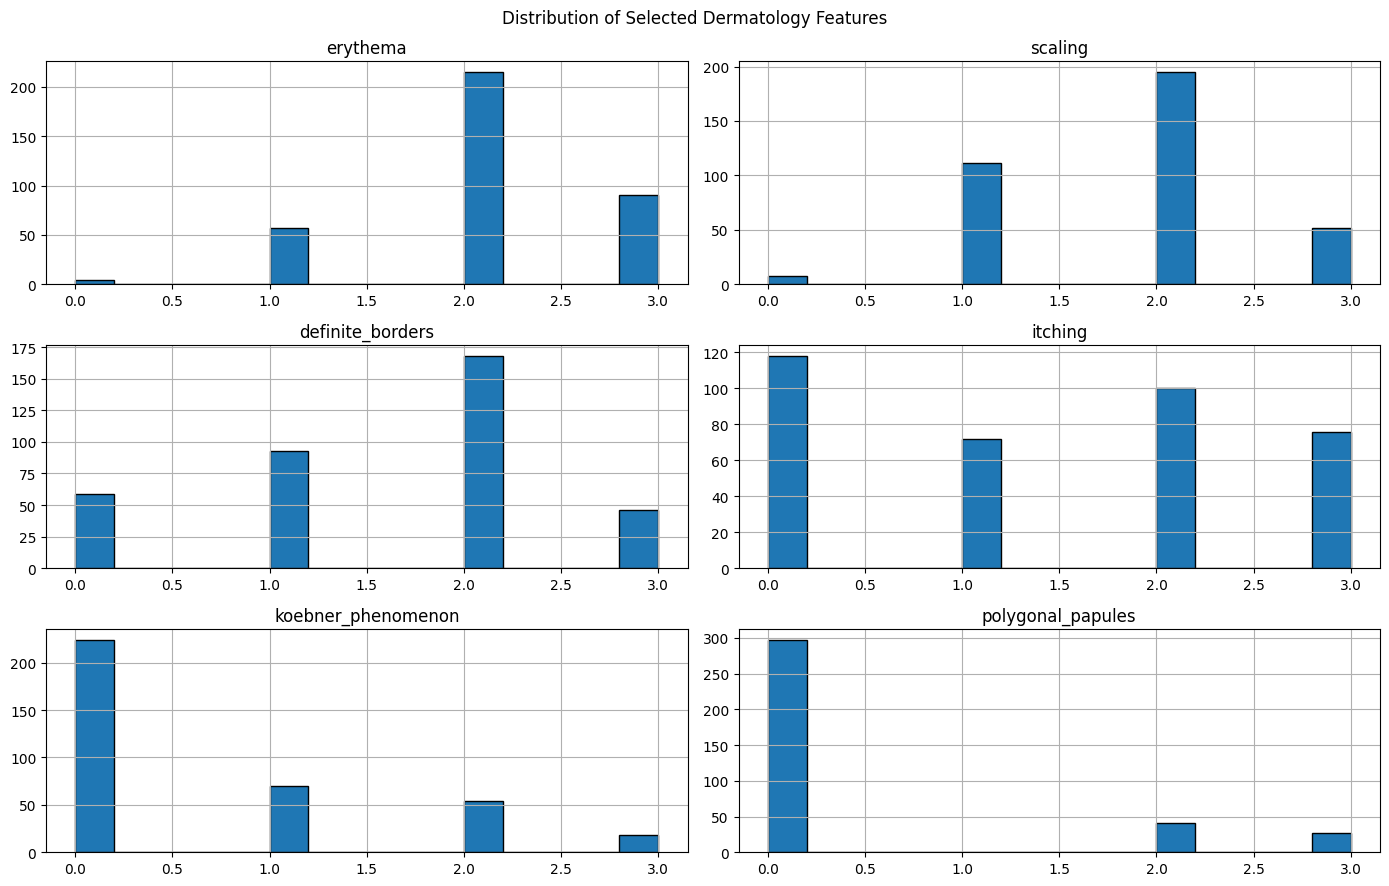

In [19]:
selected_features = X_eda.columns[:6]

X_eda[selected_features].hist(
    figsize=(14, 9),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Distribution of Selected Dermatology Features")
plt.tight_layout()
plt.show()

These graphs help you see which feature values occur frequently and whether the distributions are balanced or skewed.

CORRELATION ANALYSIS

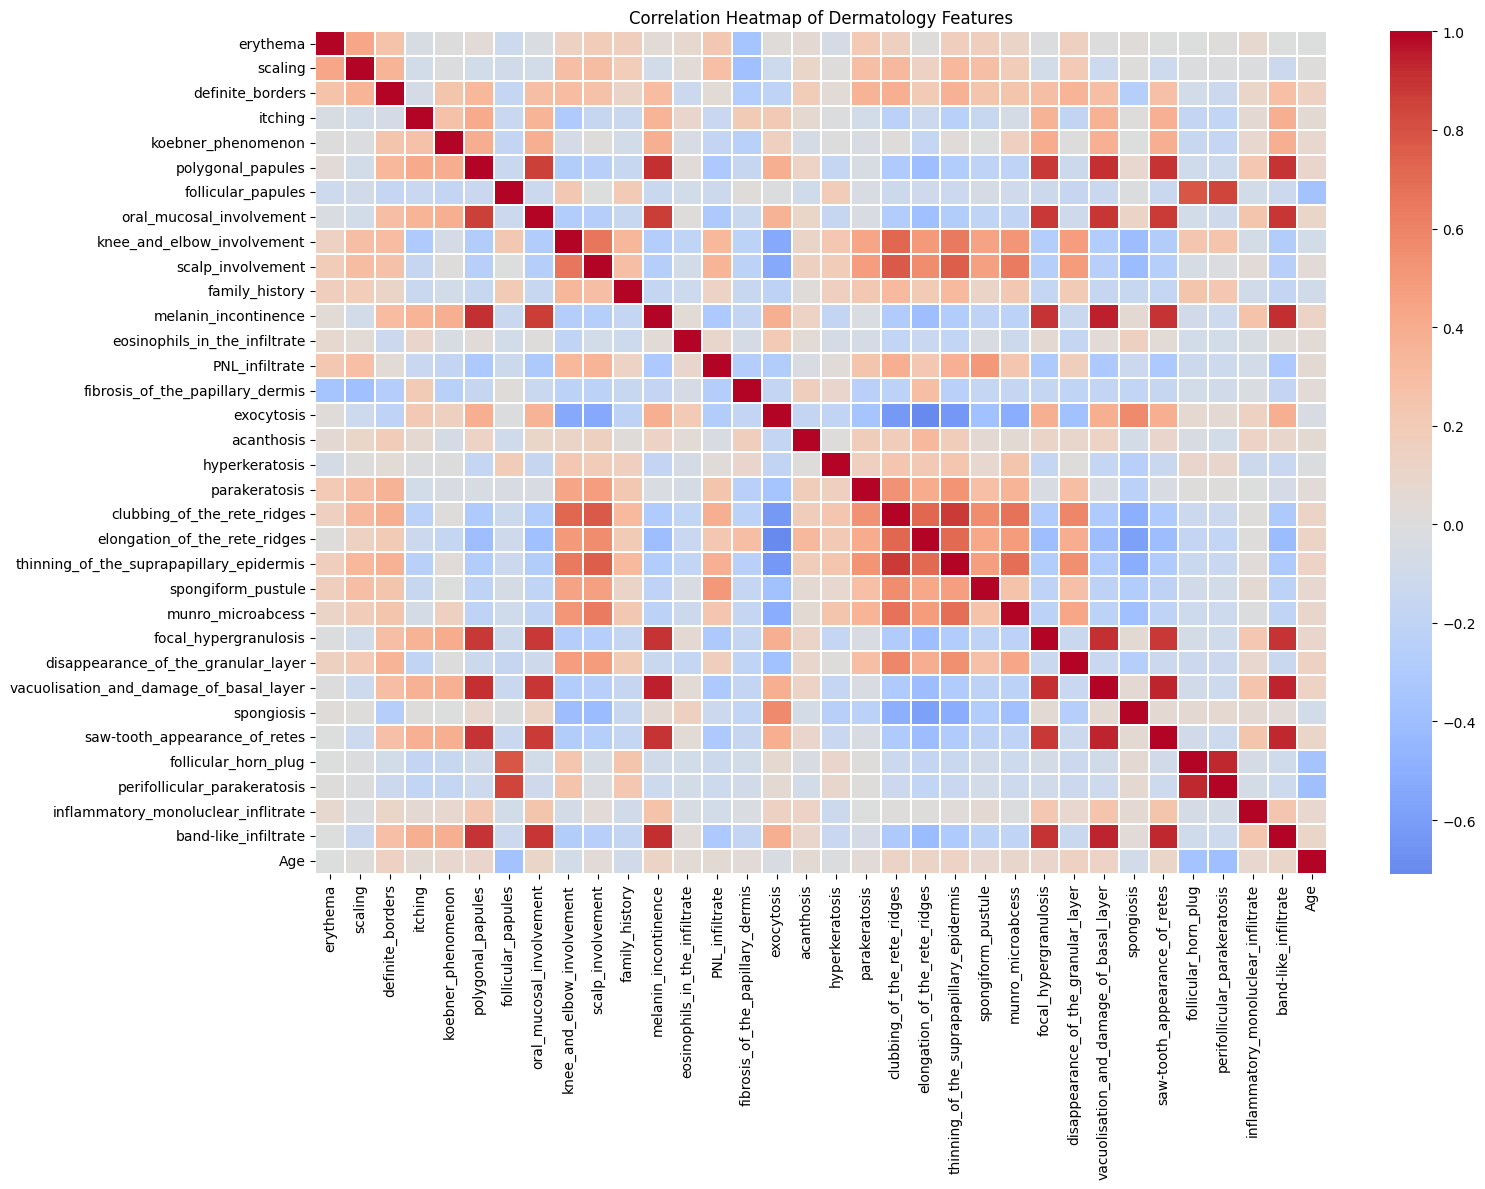

In [20]:
correlation = X_eda.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Correlation Heatmap of Dermatology Features")
plt.tight_layout()
plt.show()

Interpretation:
Values near +1 indicate a strong positive relationship.

Values near -1 indicate a strong negative relationship.

Values near 0 indicate a weak linear relationship.

DETECT POSSIBLE OUTLIERS

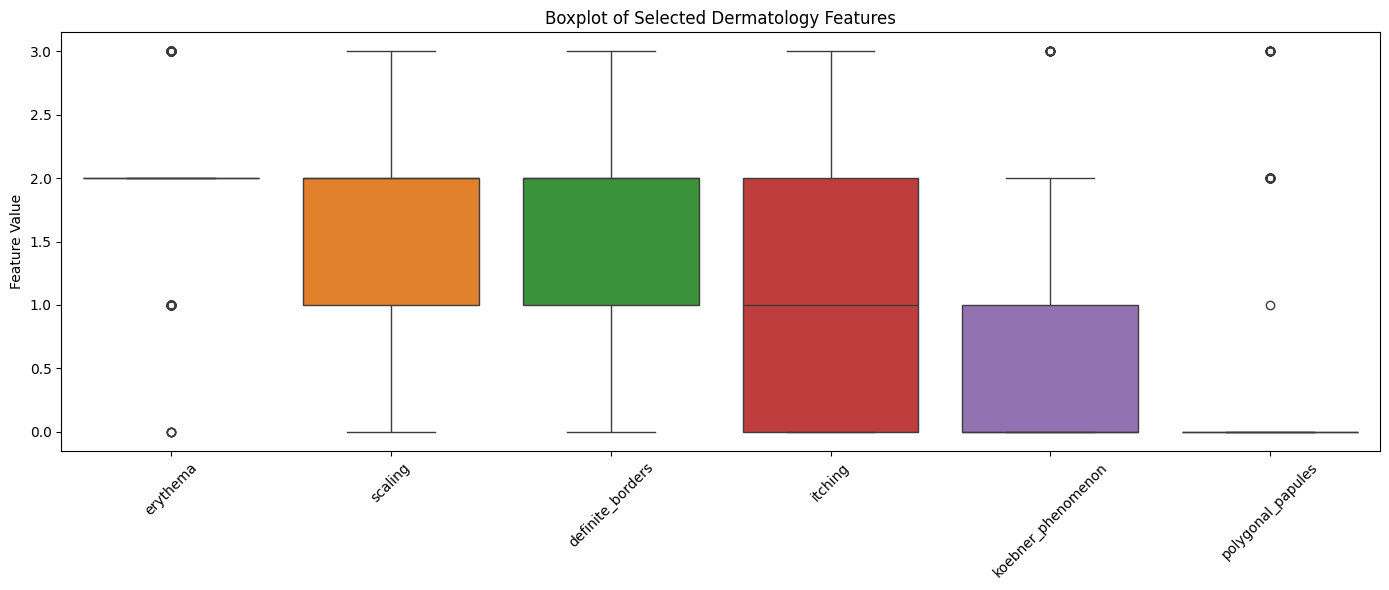

In [21]:
numeric_features = X_eda.select_dtypes(
    include=np.number
).columns.tolist()

# Select up to six features for readability
features_to_plot = numeric_features[:6]

plt.figure(figsize=(14, 6))
sns.boxplot(data=X_eda[features_to_plot])
plt.title("Boxplot of Selected Dermatology Features")
plt.xticks(rotation=45)
plt.ylabel("Feature Value")
plt.tight_layout()
plt.show()

Some features are binary or categorical codes, so values that appear as outliers may be valid clinical categories rather than errors.

FEATURES WITH MOST MISSING VALUES

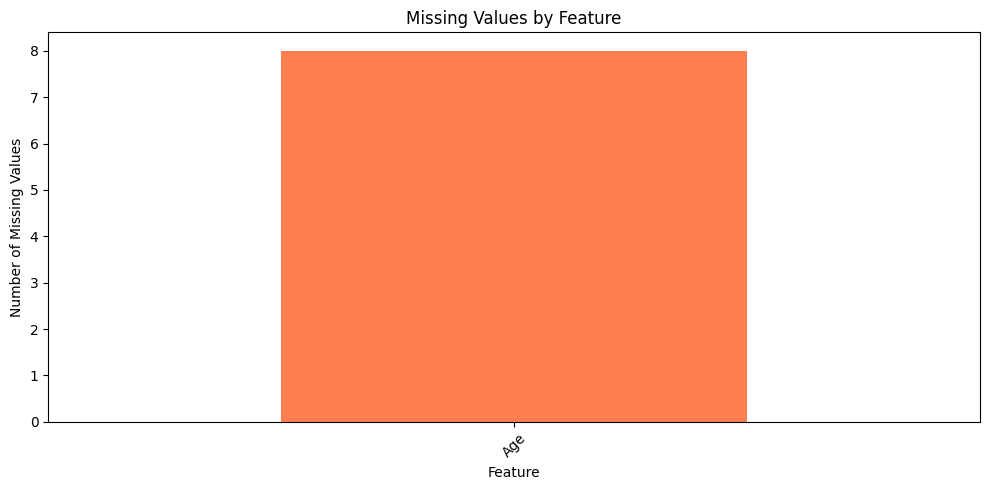

In [22]:
missing_counts = X_eda.isnull().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(
    ascending=False
)

if not missing_counts.empty:
    plt.figure(figsize=(10, 5))
    missing_counts.plot(kind="bar", color="coral")
    plt.title("Missing Values by Feature")
    plt.xlabel("Feature")
    plt.ylabel("Number of Missing Values")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found in the features.")

EDA SUMMARY

In [24]:
print("=" * 50)
print("SKIN DISORDER PREDICTION - EDA SUMMARY")
print("=" * 50)

print("Total records:", len(df))
print("Total columns:", df.shape[1])
print("Input features:", X_eda.shape[1])
print("Target column:", target_col)
print("Number of target classes:", y_eda.nunique())
print("Total missing values:", df.isnull().sum().sum())

print("\nTarget class distribution:")
print(y_eda.value_counts().sort_index())

print("\nFeatures with missing values:")
print(X_eda.isnull().sum()[X_eda.isnull().sum() > 0])


SKIN DISORDER PREDICTION - EDA SUMMARY
Total records: 366
Total columns: 35
Input features: 34
Target column: class
Number of target classes: 6
Total missing values: 8

Target class distribution:
class
1    112
2     61
3     72
4     49
5     52
6     20
Name: count, dtype: int64

Features with missing values:
Age    8
dtype: int64


In [29]:
# Clean column names
df.columns = df.columns.str.strip()

# Convert '?' and blank strings to missing values
df = df.replace(r'^\s*\?\s*$', np.nan, regex=True)
df = df.replace(r'^\s*$', np.nan, regex=True)

# Find the target column
target_column = next(
    (col for col in df.columns if col.strip().lower() == "class"),
    None
)

if target_column is None:
    raise ValueError(
        "Target column 'class' was not found. "
        "Please check the column names printed in Step 3."
    )

# Remove rows where the target is missing
df = df.dropna(subset=[target_column]).copy()

# Convert input features to numeric values
X = df.drop(columns=[target_column]).apply(
    pd.to_numeric, errors="coerce"
)

# Target class
y = pd.to_numeric(df[target_column], errors="coerce")

# Remove any rows with invalid target labels
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)

# Remove features that contain no usable values
X = X.dropna(axis=1, how="all")

print("Data cleaning completed!")
print("Number of records:", len(X))
print("Number of features:", X.shape[1])
print("Target classes:", sorted(y.unique()))
print("\nClass distribution:")
print(y.value_counts().sort_index())

Data cleaning completed!
Number of records: 366
Number of features: 34
Target classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]

Class distribution:
class
1    112
2     61
3     72
4     49
5     52
6     20
Name: count, dtype: int64


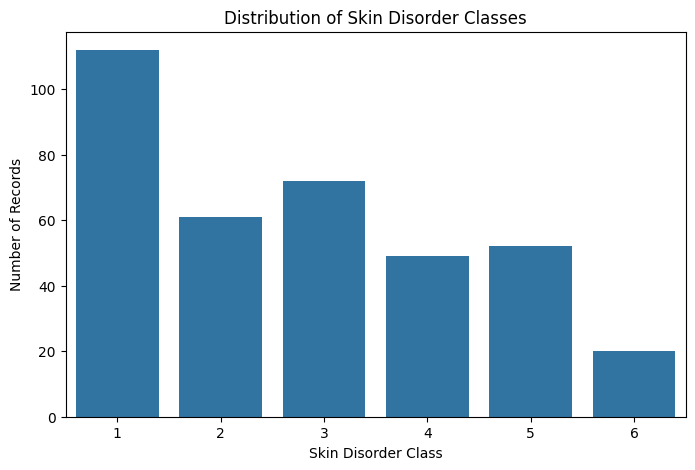

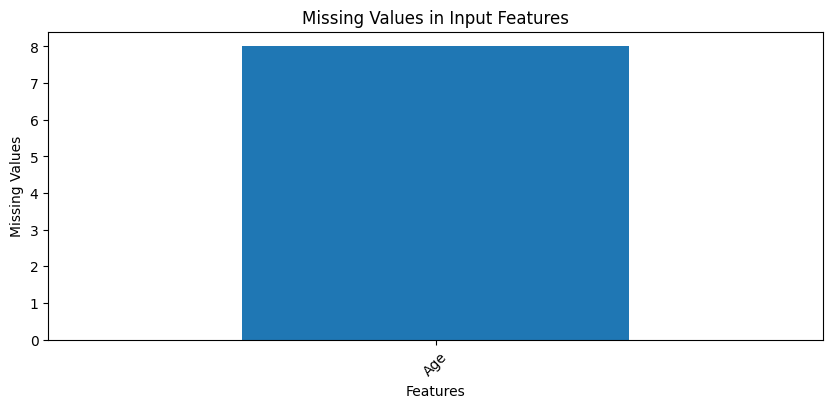

In [30]:
# Distribution of skin disorder classes
plt.figure(figsize=(8, 5))
sns.countplot(x=y)
plt.title("Distribution of Skin Disorder Classes")
plt.xlabel("Skin Disorder Class")
plt.ylabel("Number of Records")
plt.show()

# Missing values in input features
missing = X.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing) > 0:
    missing.plot(kind="bar", figsize=(10, 4))
    plt.title("Missing Values in Input Features")
    plt.xlabel("Features")
    plt.ylabel("Missing Values")
    plt.xticks(rotation=45)
    plt.show()
else:
    print("No missing values in the input features.")

SPLIT TRAIN AND TEST DATA

We'll use 80% of the data for training and 20% for testing. All three models will use the same split for a fair comparison.

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])


Training records: 292
Testing records: 74


BUILD AND TRAIN THE THREE MODELS

In [35]:
models = {
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"
        ))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            class_weight="balanced"
        ))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(
            random_state=42,
            class_weight="balanced"
        ))
    ])
}

# Train each model
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully!")

print("\nAll three models have been trained!")

Random Forest trained successfully!
SVM trained successfully!
Decision Tree trained successfully!

All three models have been trained!


COMPARE MODEL PERFORMANCE

In [36]:
results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy (%)": accuracy_score(y_test, y_pred) * 100,
        "Precision (%)": precision_score(
            y_test, y_pred, average="weighted",
            zero_division=0
        ) * 100,
        "Recall (%)": recall_score(
            y_test, y_pred, average="weighted",
            zero_division=0
        ) * 100,
        "F1-Score (%)": f1_score(
            y_test, y_pred, average="weighted",
            zero_division=0
        ) * 100
    })

results_df = pd.DataFrame(results)
results_df = results_df.round(2)

print("MODEL PERFORMANCE COMPARISON")
display(results_df.sort_values(
    by="F1-Score (%)", ascending=False
).reset_index(drop=True))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,SVM,97.30,97.75,97.30,97.30
1,Random Forest,95.95,96.07,95.95,95.95
2,Decision Tree,95.95,96.46,95.95,95.94


VISUALIZE THE MODEL COMPARISON

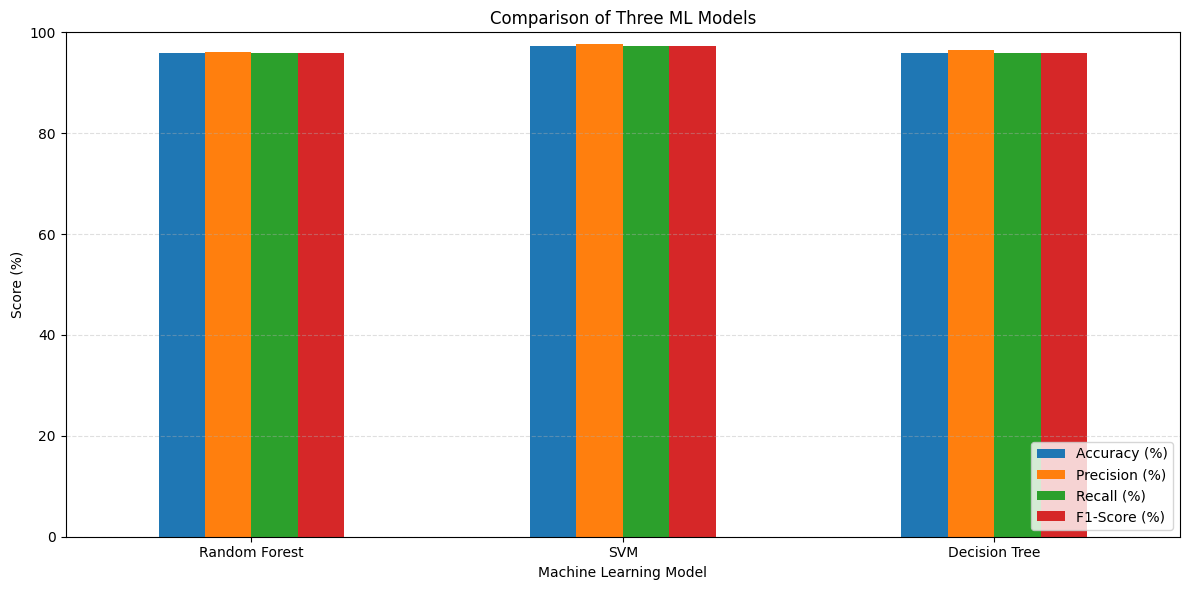

In [37]:
metrics = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-Score (%)"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 100)
)

plt.title("Comparison of Three ML Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score (%)")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

CONFUSION MATRICES

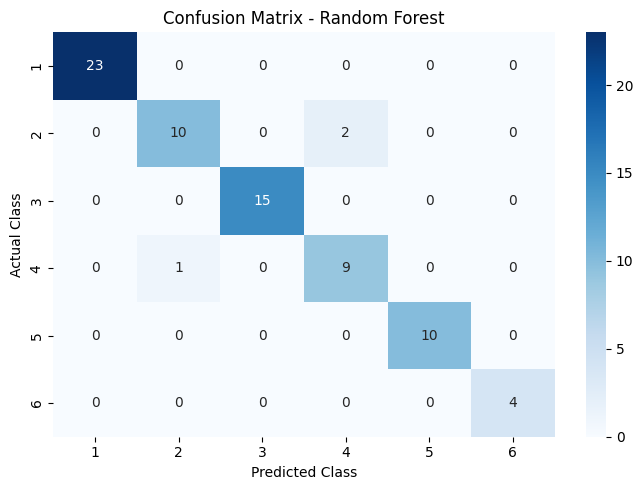

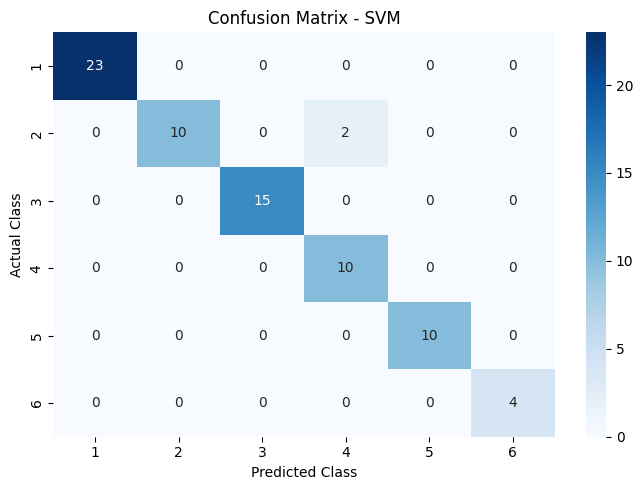

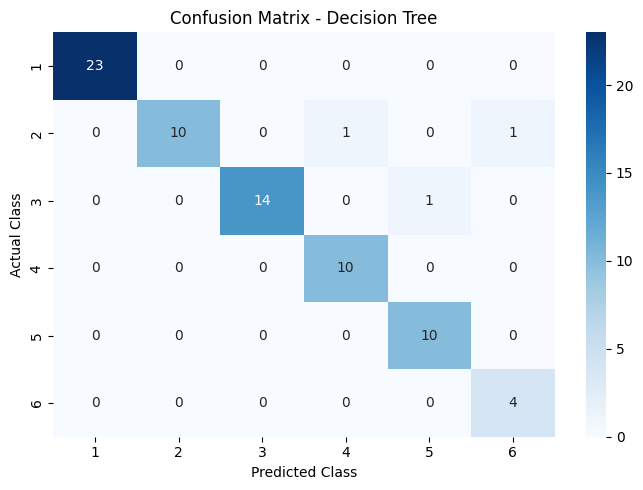

In [38]:
for name, y_pred in predictions.items():
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=sorted(y.unique()),
        yticklabels=sorted(y.unique())
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()
    plt.show()

CLASSIFICATION REPORTS

In [39]:
for name, y_pred in predictions.items():
    print("\n" + "=" * 55)
    print(f"CLASSIFICATION REPORT: {name}")
    print("=" * 55)

    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))


CLASSIFICATION REPORT: Random Forest
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.91      0.83      0.87        12
           3       1.00      1.00      1.00        15
           4       0.82      0.90      0.86        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.96        74
   macro avg       0.95      0.96      0.95        74
weighted avg       0.96      0.96      0.96        74


CLASSIFICATION REPORT: SVM
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       1.00      0.83      0.91        12
           3       1.00      1.00      1.00        15
           4       0.83      1.00      0.91        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accurac

IDENTIFY THE BEST MODEL

We'll select the model with the highest weighted F1-score, which balances precision and recall across the six classes while accounting for class sizes.

In [41]:
best_index = results_df["F1-Score (%)"].idxmax()
best_model_name = results_df.loc[best_index, "Model"]

print("BEST PERFORMING MODEL:", best_model_name)
print("-" * 40)

best_row = results_df.loc[best_index]

for metric in metrics:
    print(f"{metric}: {best_row[metric]}")



BEST PERFORMING MODEL: SVM
----------------------------------------
Accuracy (%): 97.3
Precision (%): 97.75
Recall (%): 97.3
F1-Score (%): 97.3


CONCLUSION

The Skin Disorder Prediction Using Machine Learning project was developed to classify skin disorders using the Dermatology dataset. Exploratory Data Analysis (EDA) was performed to understand the dataset, examine feature distributions, identify missing values, and analyze the distribution of the six target classes. Data preprocessing was then carried out to prepare the dataset for model training.
Three machine learning algorithms—Random Forest, Support Vector Machine (SVM), and Decision Tree—were implemented and evaluated using performance metrics such as accuracy, precision, recall, F1-score, and confusion matrices. These results help compare the models and identify the best-performing classifier for the given dataset.
In conclusion, this project demonstrates how machine learning can be applied to dermatology data for automated skin disorder classification. The system provides an educational example of predictive analytics and may support further research into computer-assisted classification. However, its predictions are not a substitute for professional medical diagnosis, and further testing with independent clinical data is required before any real-world medical use.

TEST A NEW PREDICTION

In [42]:
best_model = models[best_model_name]

sample = X_test.iloc[[0]]
actual_class = y_test.iloc[0]
predicted_class = best_model.predict(sample)[0]

print("Actual skin disorder class:", actual_class)
print("Predicted skin disorder class:", predicted_class)

if actual_class == predicted_class:
    print("Prediction matches the actual class.")
else:
    print("Prediction does not match the actual class.")

Actual skin disorder class: 2
Predicted skin disorder class: 2
Prediction matches the actual class.


This tests an existing held-out record rather than a new patient's clinical data.